<a href="https://colab.research.google.com/github/mahithamodepalli29/Customer_Segmentation_Analysis/blob/main/Predicting_House_Prices_with_Linear_Regression_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
sns.set_style("whitegrid")

In [2]:
df = pd.read_csv("data.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(4600, 18)
['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip', 'country']


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [3]:
df.info()
print("\nNulls:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("Price = 0:", (df.price == 0).sum())
print("Bedrooms = 0:", (df.bedrooms == 0).sum())
print("Bathrooms = 0:", (df.bathrooms == 0).sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   object 
 15  city           4600 non-null   object 
 16  statezip       4600 non-null   object 
 17  country        4600 non-null   object 
dtypes: float

,count,mean,std,min,25%,50%,75%,max
price,4600.0,551962.988473,563834.702547,0.0,322875.00,460943.461539,654962.50,26590000.0
bedrooms,4600.0,3.400870,0.908848,0.0,3.00,3.000000,4.00,9.0
bathrooms,4600.0,2.160815,0.783781,0.0,1.75,2.250000,2.50,8.0
sqft_living,4600.0,2139.346957,963.206916,370.0,1460.00,1980.000000,2620.00,13540.0
sqft_lot,4600.0,14852.516087,35884.436145,638.0,5000.75,7683.000000,11001.25,1074218.0
floors,4600.0,1.512065,0.538288,1.0,1.00,1.500000,2.00,3.5
waterfront,4600.0,0.007174,0.084404,0.0,0.00,0.000000,0.00,1.0
view,4600.0,0.240652,0.778405,0.0,0.00,0.000000,0.00,4.0
condition,4600.0,3.451739,0.677230,1.0,3.00,3.000000,4.00,5.0
sqft_above,4600.0,1827.265435,862.168977,370.0,1190.00,1590.000000,2300.00,9410.0


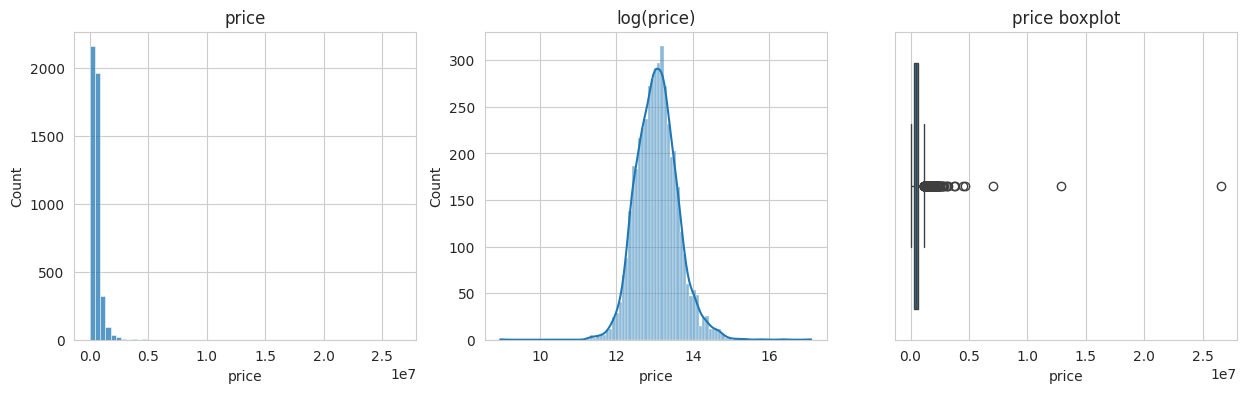

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df['price'], bins=60, ax=ax[0]); ax[0].set_title("price")
sns.histplot(np.log1p(df[df.price > 0]['price']), kde=True, ax=ax[1]); ax[1].set_title("log(price)")
sns.boxplot(x=df['price'], ax=ax[2]); ax[2].set_title("price boxplot")
plt.show()

In [6]:
print("Before:", df.shape)
df = df.drop_duplicates()
df = df[df['price'] > 0]
df = df[(df.bedrooms > 0) & (df.bathrooms > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
print("After:", df.shape)

Before: (4600, 18)
After: (4503, 18)


In [7]:
df['date'] = pd.to_datetime(df['date'])
df['house_age'] = df['date'].dt.year - df['yr_built']
df['was_renovated'] = (df['yr_renovated'] > 0).astype(int)
df = df.drop(columns=['date','street','statezip','country','yr_renovated','yr_built','sqft_above'])
print(df.shape)
df.head()

(4503, 13)


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_basement,city,house_age,was_renovated
0,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,0,Shoreline,59,1
2,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,0,Kent,48,0
3,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,Bellevue,51,0
4,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,800,Redmond,38,1
5,490000.0,2.0,1.00,880,6380,1.0,0,0,3,0,Seattle,76,1


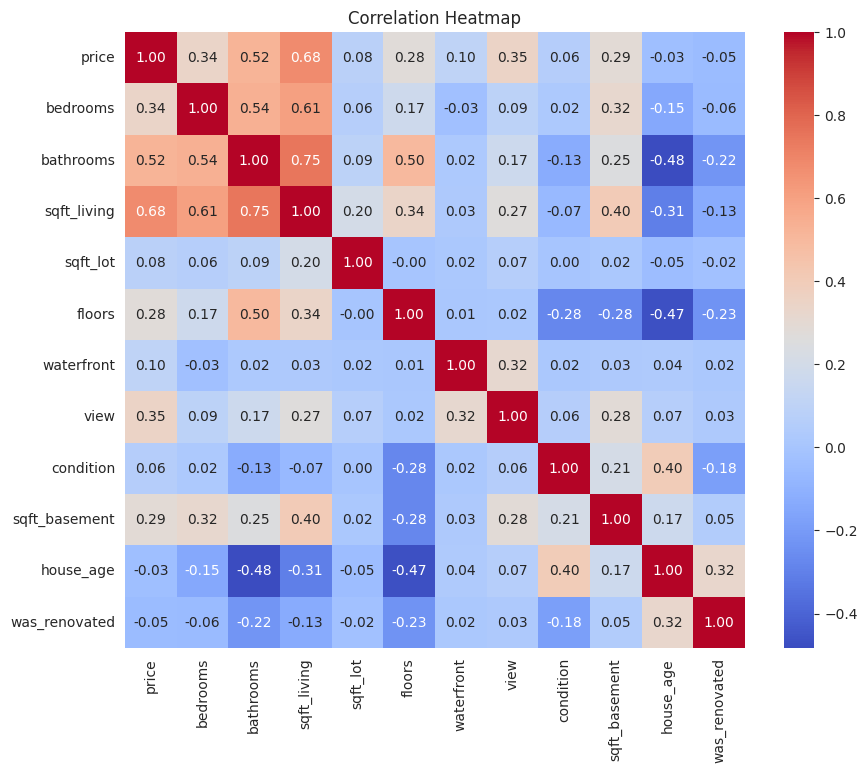

In [8]:
num = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 8))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [9]:
print(num.corr()['price'].sort_values(ascending=False))

price            1.000000
sqft_living      0.676065
bathrooms        0.520711
view             0.348390
bedrooms         0.343688
sqft_basement    0.290065
floors           0.280391
waterfront       0.102232
sqft_lot         0.083816
condition        0.061190
house_age       -0.032456
was_renovated   -0.053943
Name: price, dtype: float64


In [10]:
df = pd.get_dummies(df, columns=['city'], drop_first=True)

X = df.drop('price', axis=1)
y = np.log1p(df['price'])

print(X.shape, y.shape)
X.head()

(4503, 54) (4503,)


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_basement,house_age,...,city_SeaTac,city_Seattle,city_Shoreline,city_Skykomish,city_Snoqualmie,city_Snoqualmie Pass,city_Tukwila,city_Vashon,city_Woodinville,city_Yarrow Point
0,3.0,1.50,1340,7912,1.5,0,0,3,0,59,...,False,False,True,False,False,False,False,False,False,False
2,3.0,2.00,1930,11947,1.0,0,0,4,0,48,...,False,False,False,False,False,False,False,False,False,False
3,3.0,2.25,2000,8030,1.0,0,0,4,1000,51,...,False,False,False,False,False,False,False,False,False,False
4,4.0,2.50,1940,10500,1.0,0,0,4,800,38,...,False,False,False,False,False,False,False,False,False,False
5,2.0,1.00,880,6380,1.0,0,0,3,0,76,...,False,True,False,False,False,False,False,False,False,False


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns)

print("Train:", X_train_s.shape, " Test:", X_test_s.shape)

Train: (3602, 54)  Test: (901, 54)


In [12]:
lr = LinearRegression().fit(X_train_s, y_train)
pred = lr.predict(X_test_s)

In [13]:
mse = mean_squared_error(y_test, pred)
print("MSE (log) :", mse)
print("RMSE (log):", np.sqrt(mse))
print("R2        :", r2_score(y_test, pred))

actual, predicted = np.expm1(y_test), np.expm1(pred)
print("RMSE ($)  :", np.sqrt(mean_squared_error(actual, predicted)))
print("MAE  ($)  :", mean_absolute_error(actual, predicted))

MSE (log) : 0.07988614508546713
RMSE (log): 0.28264137185746024
R2        : 0.6829534654262067
RMSE ($)  : 164472.7080422018
MAE  ($)  : 102428.57795116924


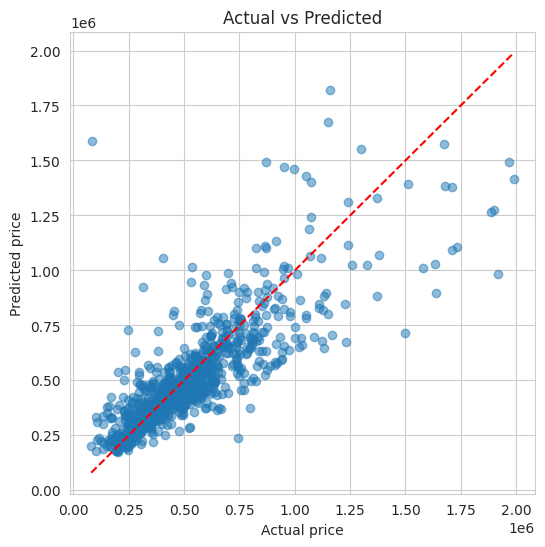

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(actual, predicted, alpha=0.5)
lims = [actual.min(), actual.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs Predicted")
plt.show()

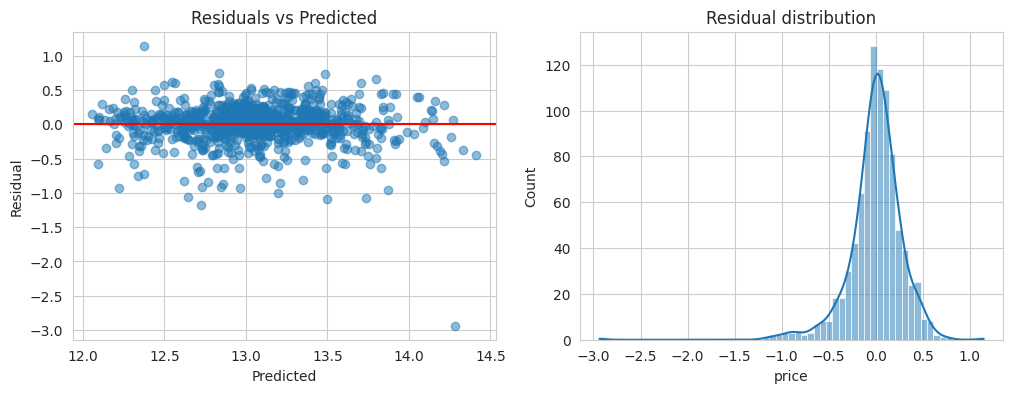

In [15]:
res = y_test - pred
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(pred, res, alpha=0.5)
ax[0].axhline(0, color='r')
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Residual")
ax[0].set_title("Residuals vs Predicted")
sns.histplot(res, kde=True, ax=ax[1])
ax[1].set_title("Residual distribution")
plt.show()

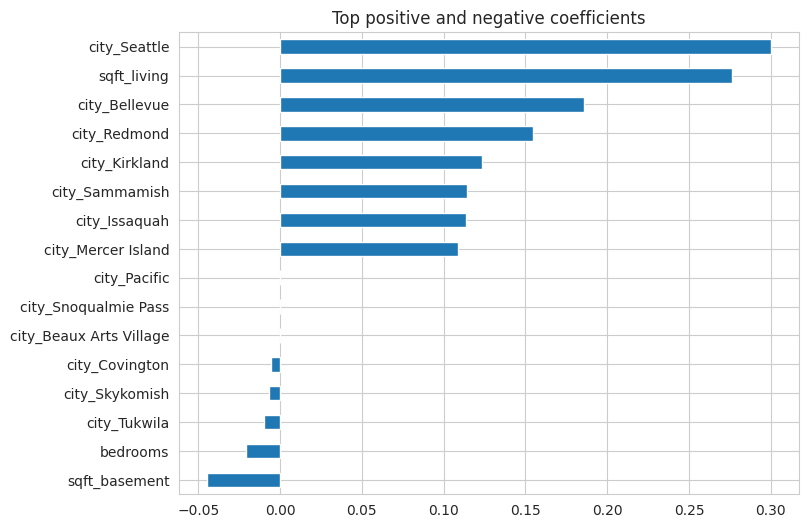

In [16]:
coef = pd.Series(lr.coef_, index=X.columns).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
top.plot(kind='barh', figsize=(8, 6))
plt.title("Top positive and negative coefficients")
plt.show()

In [17]:
print("Highest positive impact:\n", coef.tail(5))
print("\nHighest negative impact:\n", coef.head(5))

Highest positive impact:
 city_Kirkland    0.123486
city_Redmond     0.154554
city_Bellevue    0.185484
sqft_living      0.276205
city_Seattle     0.300088
dtype: float64

Highest negative impact:
 sqft_basement    -0.044388
bedrooms         -0.020907
city_Tukwila     -0.009997
city_Skykomish   -0.006590
city_Covington   -0.005494
dtype: float64


In [18]:
rows = []
for n, m in [("Linear", LinearRegression()),
             ("Ridge", Ridge(alpha=10)),
             ("Lasso", Lasso(alpha=0.001))]:
    m.fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    mse = mean_squared_error(y_test, p)
    rows.append([n, mse, np.sqrt(mse), r2_score(y_test, p)])

results = pd.DataFrame(rows, columns=["Model", "MSE", "RMSE", "R2"])
results

,Model,MSE,RMSE,R2
0,Linear,0.079886,0.282641,0.682953
1,Ridge,0.079967,0.282785,0.682631
2,Lasso,0.079879,0.282629,0.682982


In [19]:
lasso = Lasso(alpha=0.001).fit(X_train_s, y_train)
print("Features set to zero:", (lasso.coef_ == 0).sum(), "of", len(lasso.coef_))

Features set to zero: 4 of 54


Conclusion

Objective: To build a Linear Regression model that predicts house prices from features such as living area, bathrooms, view, waterfront, house age and city.

Data and preparation: The dataset had 4,600 records and 18 columns, with no missing values or duplicates. I removed rows with a price of 0 (49 rows) and rows with zero bedrooms or bathrooms (2 rows each). I also removed the top 1% of prices as extreme outliers, which left about ___ rows. I engineered house_age and was_renovated, dropped sqft_above to avoid multicollinearity, and One-Hot Encoded city. The target was log-transformed because price was strongly right-skewed.

Model performance: On the 20% test set, the Linear Regression model achieved:

R² = ___ (the model explains about ___% of the variation in log price)
RMSE (log scale) = ___
RMSE ($) = ___ and MAE ($) = ___

Key findings:

The strongest positive drivers of price were ___, ___ and ___.
The strongest negative drivers were ___ and ___.
The residuals were scattered randomly around zero and roughly bell-shaped, so the linear regression assumptions were reasonably satisfied.
Ridge and Lasso regression gave almost the same R² as plain Linear Regression, so overfitting was not a problem.

Limitations:

A linear model cannot capture every non-linear relationship in the data.
The model uses no street-level or neighbourhood-level information beyond city.
Removing the top 1% of prices means the model is less reliable for very expensive luxury homes.

Future improvements: Try tree-based models such as Random Forest or Gradient Boosting, and add more location features such as zip-code-level data.